# River water quality

Seasonal and spatial analysis of oxygen and nitrate for the TU Dortmund M.Sc. Data Science application, summer semester 2027. The notebook reproduces descriptive outputs and presents the full factorial analysis. The ten-page PDF is in `report/river_water_quality_report.pdf`.

In [1]:
from pathlib import Path
import runpy
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'src/analyze.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src/analyze.py').exists():
    raise RuntimeError('Open this notebook from the project root or notebooks folder.')
analysis = runpy.run_path(str(ROOT / 'src/analyze.py'))
data = analysis['main']()

Validated 900 rows; saved descriptive tables and two figures.
Spring minus autumn means (mg/L):
oxygen_mgL     0.1519
nitrate_mgL    0.8707


## Data validation

The script checks the 900-row schema, missingness, unique IDs, valid concentrations, and 45 observations in each section-season cell. IDs do not establish repeated measurements or sampling order.

In [2]:
display(data.head())
display(pd.read_csv(ROOT / 'outputs/tables/cell_counts.csv'))

,ID,river_section,saison,nitrate_mgL,oxygen_mgL
0,1,A1_headwaters,spring,5.540,10.711
1,2,A1_headwaters,spring,3.328,9.937
2,3,A1_headwaters,spring,5.742,10.499
3,4,A1_headwaters,spring,7.822,10.405
4,5,A1_headwaters,spring,8.843,10.245


,river_section,saison,n
0,A1_headwaters,spring,45
1,A1_headwaters,summer,45
2,A1_headwaters,autumn,45
3,A1_headwaters,winter,45
4,A2_upper_course,spring,45
5,A2_upper_course,summer,45
6,A2_upper_course,autumn,45
7,A2_upper_course,winter,45
8,A3_middle_course,spring,45
9,A3_middle_course,summer,45


## Descriptive tables

Concentrations are in mg/L. SD uses the sample denominator n-1; quartiles use pandas linear interpolation. Pooled summaries combine groups with different means.

In [3]:
display(pd.read_csv(ROOT / 'outputs/tables/by_season.csv').round(3))
display(pd.read_csv(ROOT / 'outputs/tables/by_section.csv').round(3))
display(pd.read_csv(ROOT / 'outputs/tables/season_mean_differences.csv'))

,saison,outcome,n,mean,sd,median,q1,q3,minimum,maximum,iqr
0,spring,nitrate_mgL,225,9.289,2.591,9.652,7.176,11.215,1.510,14.786,4.039
1,spring,oxygen_mgL,225,9.531,0.857,9.550,8.976,10.129,7.479,12.167,1.153
2,summer,nitrate_mgL,225,10.342,2.744,10.708,8.357,12.525,3.963,16.444,4.168
3,summer,oxygen_mgL,225,7.040,0.930,6.975,6.348,7.759,4.608,9.809,1.411
4,autumn,nitrate_mgL,225,8.418,2.752,8.568,6.627,10.510,1.999,16.377,3.883
5,autumn,oxygen_mgL,225,9.379,0.888,9.514,8.742,10.007,6.613,12.107,1.265
6,winter,nitrate_mgL,225,7.198,2.442,7.552,5.287,8.943,1.562,13.211,3.656
7,winter,oxygen_mgL,225,9.935,0.779,9.872,9.427,10.400,7.703,12.029,0.973


,river_section,outcome,n,mean,sd,median,q1,q3,minimum,maximum,iqr
0,A1_headwaters,nitrate_mgL,180,5.350,1.708,5.354,4.026,6.658,1.510,11.053,2.631
1,A1_headwaters,oxygen_mgL,180,9.231,1.230,9.498,8.469,10.139,6.199,11.646,1.670
2,A2_upper_course,nitrate_mgL,180,7.343,1.789,7.222,6.273,8.590,3.732,12.363,2.317
3,A2_upper_course,oxygen_mgL,180,9.005,1.280,9.256,8.209,9.891,5.705,11.794,1.682
4,A3_middle_course,nitrate_mgL,180,9.328,1.809,9.491,8.001,10.642,4.061,13.095,2.641
5,A3_middle_course,oxygen_mgL,180,8.990,1.409,9.284,8.002,10.008,4.608,12.167,2.005
6,A4_lower_course,nitrate_mgL,180,10.570,1.858,10.450,9.221,12.088,6.328,15.362,2.867
7,A4_lower_course,oxygen_mgL,180,8.694,1.465,8.989,7.808,9.785,5.033,11.705,1.977
8,A5_mouth,nitrate_mgL,180,11.467,1.985,11.398,10.167,13.013,6.644,16.444,2.846
9,A5_mouth,oxygen_mgL,180,8.936,1.665,9.419,7.873,10.116,4.987,11.857,2.244


,Unnamed: 0,spring_minus_autumn_mg_L
0,oxygen_mgL,0.151938
1,nitrate_mgL,0.870662


## Figure 1: seasonal distributions

Each season has 225 observations pooled over five sections. Boxes span the 25th to 75th percentiles; the line is the median. Whiskers reach the furthest observations within 1.5 IQR of the box; circles show observations beyond the whiskers, which are retained.

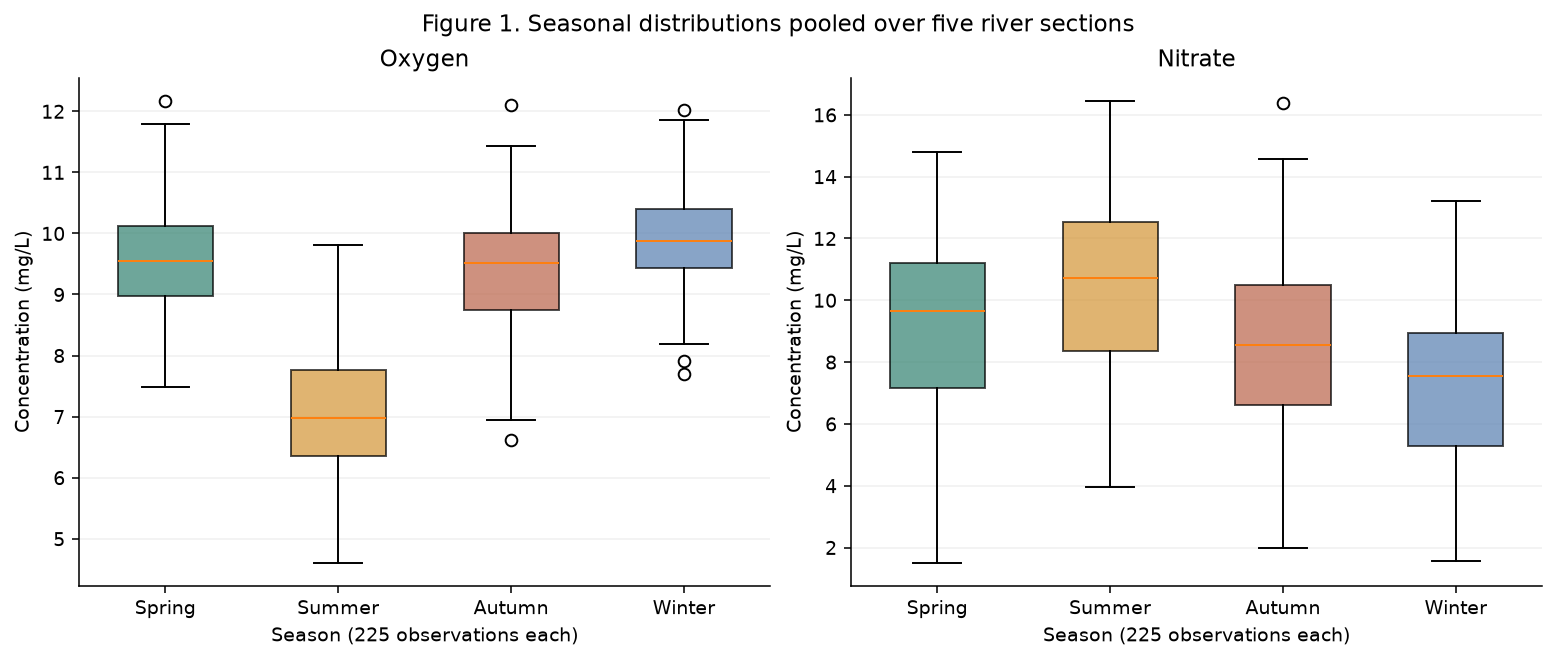

In [4]:
display(Image(filename=str(ROOT / 'outputs/figures/seasonal_distributions.png')))

## Figure 2: section means by season

Each point averages 45 observations. Lines connect ordered river sections to help compare the patterns; they do not model continuous spatial variation or imply interpolation. These plots do not display uncertainty.

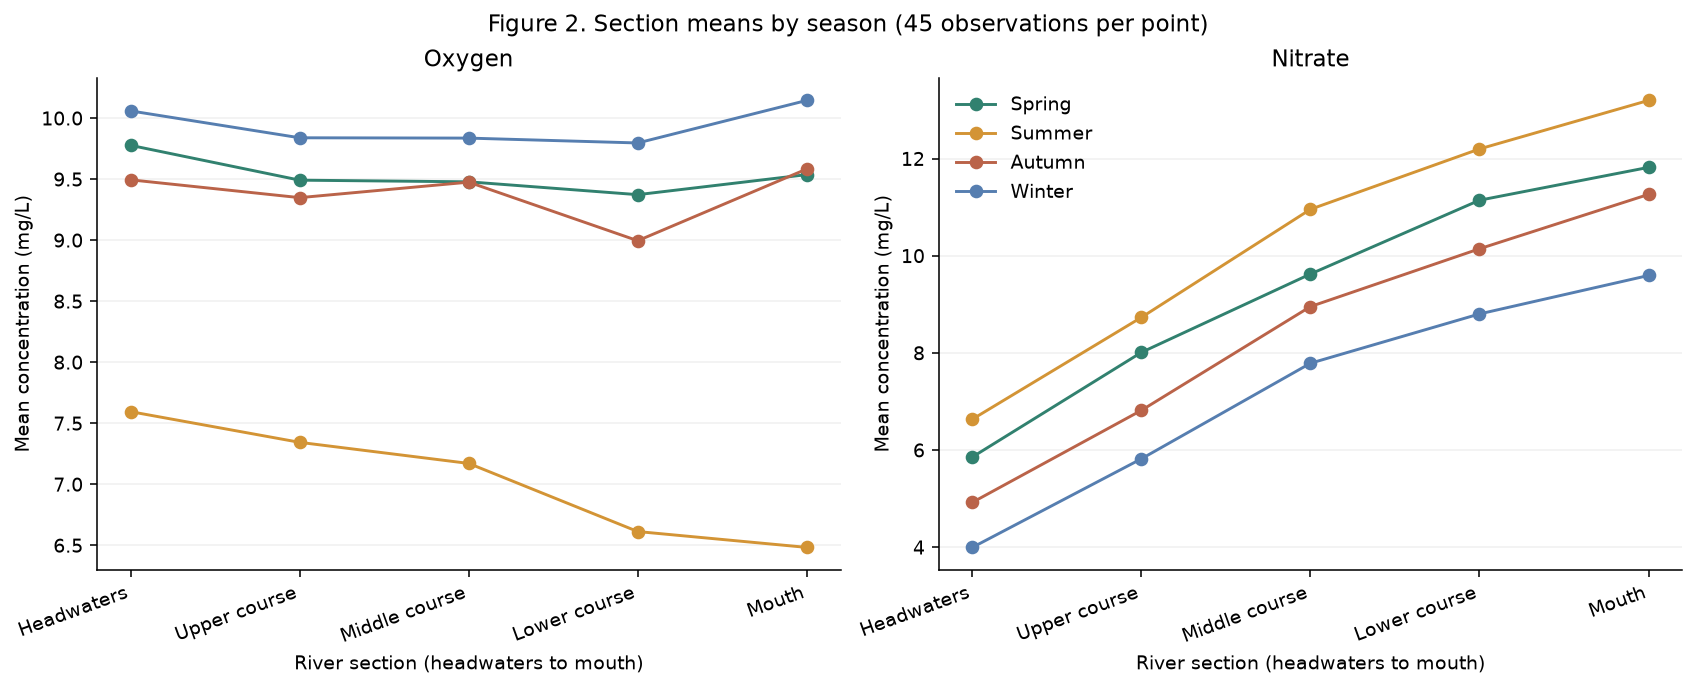

In [5]:
display(Image(filename=str(ROOT / 'outputs/figures/section_season_means.png')))

## Hypothesis tests

Full section-by-season cell-means models with HC3 covariance. Two seasonal contrasts, two section omnibus tests, twenty section-pair comparisons, and two interaction tests form one Holm family of 26 tests at alpha = 0.05. Intervals are pointwise 95% intervals. Independence is assumed, not established by the CSV.

In [6]:
import sys
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from inference import main as infer
infer()
tests = pd.read_csv(ROOT / 'outputs/tables/hypothesis_tests.csv')
display(tests.loc[tests.kind == 'season'].round(6))
display(tests.loc[tests.kind.isin(['section_omnibus', 'interaction'])])
display(tests.loc[tests.kind == 'section_pair'])

    outcome            kind                         contrast  estimate        p_holm  reject_005
 oxygen_mgL          season                  spring - autumn  0.151938  3.236086e-01       False
 oxygen_mgL section_omnibus     equal section marginal means       NaN  1.550468e-07        True
 oxygen_mgL     interaction no section by season interaction       NaN  3.328881e-05        True
 oxygen_mgL    section_pair                          A1 - A2  0.225744  5.538279e-02       False
 oxygen_mgL    section_pair                          A1 - A3  0.241206  5.538279e-02       False
 oxygen_mgL    section_pair                          A1 - A4  0.536967  1.421891e-09        True
 oxygen_mgL    section_pair                          A1 - A5  0.294322  5.936618e-03        True
 oxygen_mgL    section_pair                          A2 - A3  0.015461  1.000000e+00       False
 oxygen_mgL    section_pair                          A2 - A4  0.311222  3.493835e-03        True
 oxygen_mgL    section_pair   

,outcome,kind,contrast,wald_chi2,df,p_raw,estimate,se,z,ci_low,ci_high,p_holm,reject_005
0,oxygen_mgL,season,spring - autumn,3.412057,1,0.064722,0.151938,0.082254,1.847175,-0.009277,0.313153,0.323609,False
13,nitrate_mgL,season,spring - autumn,37.732380,1,0.000000,0.870662,0.141740,6.142669,0.592857,1.148468,0.000000,True


,outcome,kind,contrast,wald_chi2,df,p_raw,estimate,se,z,ci_low,ci_high,p_holm,reject_005
1,oxygen_mgL,section_omnibus,equal section marginal means,42.702752,4,1.192668e-08,NaN,NaN,NaN,NaN,NaN,1.550468e-07,True
2,oxygen_mgL,interaction,no section by season interaction,48.297586,12,2.774068e-06,NaN,NaN,NaN,NaN,NaN,3.328881e-05,True
14,nitrate_mgL,section_omnibus,equal section marginal means,2112.208161,4,0.000000e+00,NaN,NaN,NaN,NaN,NaN,0.000000e+00,True
15,nitrate_mgL,interaction,no section by season interaction,10.527540,12,5.697820e-01,NaN,NaN,NaN,NaN,NaN,1.000000e+00,False


,outcome,kind,contrast,wald_chi2,df,p_raw,estimate,se,z,ci_low,ci_high,p_holm,reject_005
3,oxygen_mgL,section_pair,A1 - A2,7.022687,1,8.048335e-03,0.225744,0.085185,2.650035,0.058784,0.392705,5.538279e-02,False
4,oxygen_mgL,section_pair,A1 - A3,7.053325,1,7.911827e-03,0.241206,0.090822,2.655810,0.063198,0.419213,5.538279e-02,False
5,oxygen_mgL,section_pair,A1 - A4,42.052221,1,8.886821e-11,0.536967,0.082804,6.484768,0.374673,0.699260,1.421891e-09,True
6,oxygen_mgL,section_pair,A1 - A5,11.795747,1,5.936618e-04,0.294322,0.085696,3.434494,0.126361,0.462283,5.936618e-03,True
7,oxygen_mgL,section_pair,A2 - A3,0.026969,1,8.695562e-01,0.015461,0.094147,0.164222,-0.169065,0.199987,1.000000e+00,False
8,oxygen_mgL,section_pair,A2 - A4,12.963509,1,3.176214e-04,0.311222,0.086439,3.600487,0.141805,0.480639,3.493835e-03,True
9,oxygen_mgL,section_pair,A2 - A5,0.590897,1,4.420723e-01,0.068578,0.089213,0.768698,-0.106276,0.243432,1.000000e+00,False
10,oxygen_mgL,section_pair,A3 - A4,10.335228,1,1.305150e-03,0.295761,0.091999,3.214845,0.115447,0.476075,1.174635e-02,True
11,oxygen_mgL,section_pair,A3 - A5,0.315203,1,5.745045e-01,0.053117,0.094610,0.561430,-0.132315,0.238548,1.000000e+00,False
12,oxygen_mgL,section_pair,A4 - A5,7.788984,1,5.256576e-03,-0.242644,0.086942,-2.790875,-0.413048,-0.072241,4.205261e-02,True


## Model diagnostics

The Q-Q plot compares ordered residuals with theoretical standard-normal quantiles. An approximately straight pattern supports the absence of a strong distributional departure. Residual-versus-fitted plots inspect spread and extreme observations; neither plot tests independence.

,outcome,min_cell_sd,max_cell_sd,max_min_cell_variance_ratio,residual_skewness,residual_excess_kurtosis,max_abs_standardized_residual,R_squared,residual_df
0,oxygen_mgL,0.6484,1.0904,2.8281,-0.0092,0.1584,3.4717,0.6651,880
1,nitrate_mgL,1.1808,1.7462,2.1869,-0.0085,-0.0214,3.6339,0.7596,880


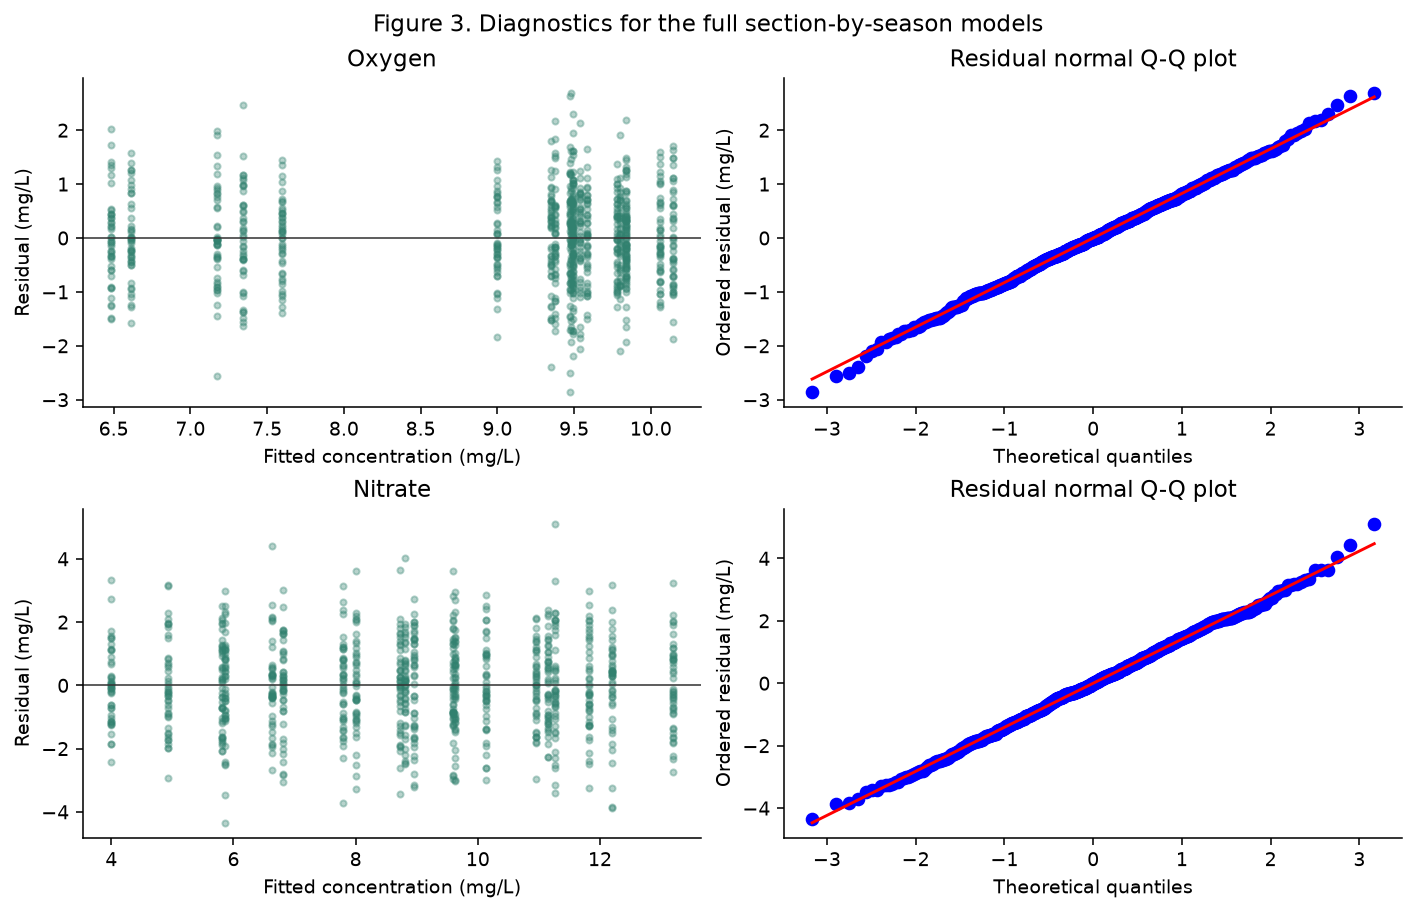

In [7]:
display(pd.read_csv(ROOT / 'outputs/tables/model_diagnostics.csv').round(4))
display(Image(filename=str(ROOT / 'outputs/figures/model_diagnostics.png')))

## Interpretation

Nitrate is higher in spring than autumn after correction; oxygen does not reject the seasonal null. All nitrate section pairs differ. Oxygen differs for A1-A4, A1-A5, A2-A4, A3-A4, and A4-A5 when averaged across seasons. Its significant interaction limits interpretation of pooled section differences. See the report for mathematical definitions, method references, and limitations.